# Links to help get started

* [A few example and links](https://github.com/kstrm/Starting-out-with-python)

# Cell types

## Markdown... 

- good for writting. Can use standard markdown formatting (googgle if you don't know)
- Can use Latex (the notebook uses MathJax)

For example. Here is an equation inline: $F = ma$. And, here's an equation in display form:

$$ E = \frac{V^2}{2g}+y $$

You can also use standard LaTex "equation environment" in:

\begin{equation}
\frac{\partial (AC)}{\partial t}+\frac{\partial (AUC)}{\partial x}=\frac{\partial}{\partial x}\left(AD\frac{\partial C}{\partial x}\right) +  b \left(E_b - D_b \right)
\end{equation}

Equation reference is not yet available

## Code

"code" cell block are the computations are actually performed.

# Let's get started

In [1]:
# Import NumPy as np and matplotlib.pyplot as plt.
import numpy as np
import matplotlib.pyplot as plt

# the the following line uncommented for nice looking plots on a retina display... comment out when downloading as "PDF via LaTeX"
# %config InlineBackend.figure_format='retina' 

# two lines below sets the output plots to pdf (good when using download as "PDF via LaTeX")... comment out when running on a retina display in a browser 
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png','pdf')

# will need for solver
from scipy.optimize import fsolve

## Arrays

In [2]:
# 100 pt array that ranges from 0 to 10*pi (float)
x = np.linspace(0,10*np.pi,100)

# 100 pt array of integers ranging from 0 to 100-1
xint = np.arange(100)

In [3]:
# returns the x values from spots 0, 1, 2 in the array
x[0:3]

array([0.        , 0.31733259, 0.63466518])

In [4]:
# returns the xint values from spots 0, 1, 2 in the array
xint[0:3]

array([0, 1, 2])

In [5]:
# create y1 as being the sin of x
y1 = np.sin(x)

# create y2 as y1 * xint
y2 = y1*xint

# create y3 as x^2
y3 = x**2

## Plotting

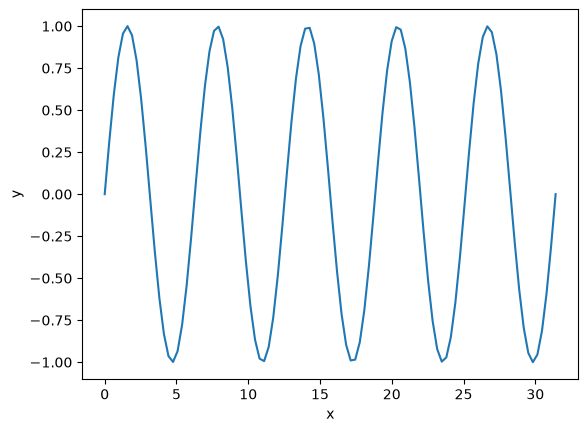

In [6]:
# plot y1 vs x
plt.plot(x,y1)
plt.xlabel('x')
plt.ylabel('y');

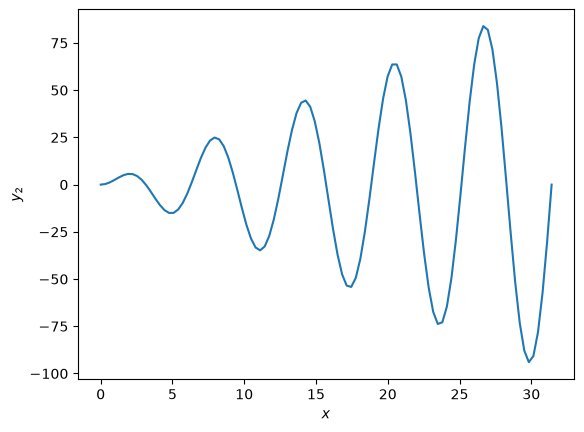

In [7]:
# plot y2 vs x
plt.plot(x,y2)
plt.xlabel('$x$')
plt.ylabel('$y_2$');

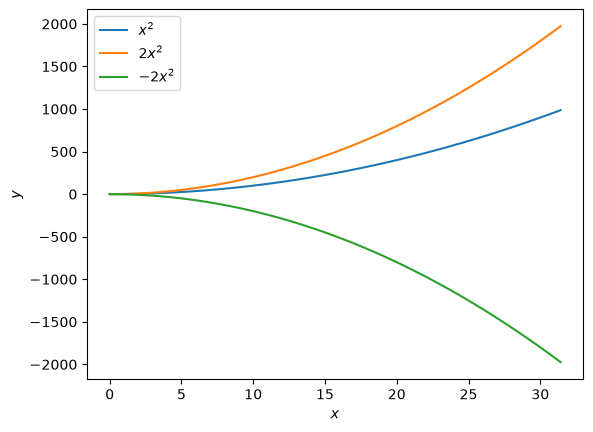

In [8]:
# plot several lines on the same figure

fig,ax = plt.subplots()
ax.plot(x, y3, label = '$x^2$')
ax.plot(x, y3*2, label = '$2x^2$')
ax.plot(x, y3*(-2), label = '$-2x^2$')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
plt.legend(loc=2);

## Define a function

The shear veloctiy for uniform open channel flow is defined as, $u_*=(ghS)^{1/2}$, where $g$ is the accereration of gravity, $h$ is the flow depth, and $S$ is the channel bed slope.

In [9]:
# the shear velocity

def shearvel(g,h,S):
    return np.sqrt(g*h*S)

In [10]:
shearvel(9.81,2,0.0003)

np.float64(0.07672027111526653)

## Solve an implicit equation

use a defined function + fslove to the Colebrook equation:

$$ \frac{1}{\sqrt{f}}=-0.86\ln\left(\frac{e}{3.7D}+\frac{2.51}{R_e\sqrt{f}}\right) $$

Goal: sovle for $f$ given $e$, $D$, and $R_e$

We will use the fsolve function in scipy: f_solution = fsolve(defname,fguess, args=(list))

In [11]:
def colebrook(f,e,D,Re):
    return (1/np.sqrt(f))+0.86*np.log((e/(3.7*D))+(2.51/(Re*np.sqrt(f))))

e = 0.00015
D = 10/100
Re = 10**5

fguess = 0.015

f_solution = fsolve(colebrook,fguess, args=(e,D,Re))

print('The Darcy Weisbach friction factor f is =', f_solution)

print('The Darcy Weisbach friction factor f is =', np.around(f_solution,decimals=3))

The Darcy Weisbach friction factor f is = [0.02419449]
The Darcy Weisbach friction factor f is = [0.024]
